# 4. Устойчивость разностных схем

Проведём два расчёта. В первом зададим начальную температуру косинусом. Во втором возьмём тот же косинус, но в чётных узлах прибавим одну сотую, а в нечётных вычтем одну сотую. Сначала два графика почти совпадают. Что станет с этой разницей через несколько шагов?

## 1. Как меняется малое возмущение?

Уравнение диффузии $u_t=\chi u_{xx}$, где $\chi>0$, описывает сглаживание температуры. На периодической сетке с шагом $h=1/N$ явная разностная схема имеет вид

$$
U_k^{s+1}
=
U_k^s+r\bigl(U_{k+1}^s-2U_k^s+U_{k-1}^s\bigr),
\qquad
r=\frac{\chi\tau}{h^2}.
$$

Здесь $k$ — номер узла, $s$ — номер шага по времени. Буквой $U$ обозначим первый расчёт, буквой $V$ — второй. Их начальные данные отличаются на

$$
\delta_k^0=V_k^0-U_k^0=0{,}01(-1)^k.
$$

Вычтем уравнение для $U$ из уравнения для $V$. Благодаря линейности схемы разность $\delta^s=V^s-U^s$ подчиняется **той же самой формуле**. А для чередующегося профиля оба соседа имеют знак, противоположный центральному значению. Поэтому один шаг особенно прост:

$$
\delta_k^1
=\delta_k^0+r\bigl(-\delta_k^0-2\delta_k^0-\delta_k^0\bigr)
=(1-4r)\delta_k^0.
$$

При $r=0{,}4$ множитель равен $-0{,}6$. Разница между расчётами меняет знак и затухает. При $r=0{,}5$ множитель равен $-1$, и разница сохраняет величину. При $r=0{,}6$ множитель равен $-1{,}4$. За восемь шагов начальная сотая превращается примерно в $0{,}148$, за шестнадцать — уже в $2{,}18$.

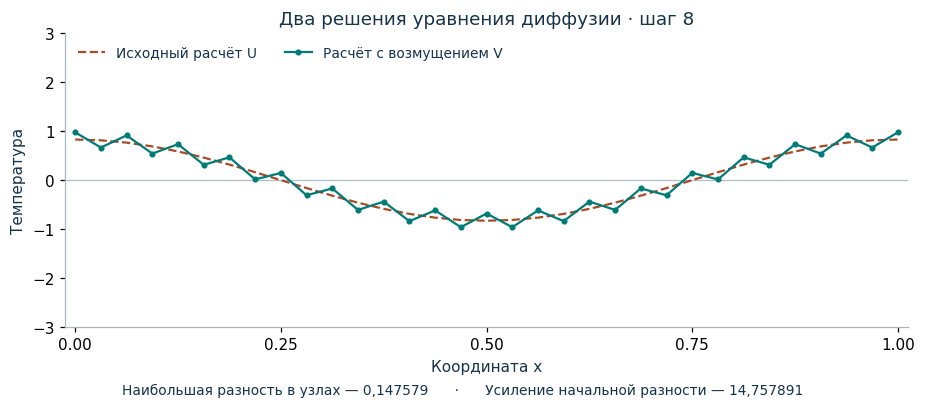

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as w
    from IPython.display import clear_output, display, Image
    from io import BytesIO
except ImportError:
    w = None

INK, TEAL, RUST = "#15334A", "#007C78", "#A84C26"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#A8B8BF", "axes.labelcolor": INK,
                     "text.color": INK, "font.size": 10, "axes.titlesize": 12,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})


def decimal(x, digits=3):
    return f"{x:.{digits}f}".rstrip("0").rstrip(".").replace(".", ",").replace("-", "−")


def experiment(figure, choices, curves=(), play=None):
    defaults = {key: value for key, (_, _, value) in choices.items()}
    if w is None:
        figure(**defaults)
        plt.show()
        return
    selectors = {}
    for key, (label, options, value) in choices.items():
        kwargs = dict(value=value, description=label, style={"description_width": "initial"},
                      layout=w.Layout(width="300px", max_width="100%"))
        if isinstance(options, range):
            selectors[key] = w.IntSlider(min=options[0], max=options[-1], step=options.step,
                                         continuous_update=False, **kwargs)
        else:
            selectors[key] = w.Dropdown(options=options, **kwargs)
    toggles = [w.ToggleButton(value=True, description=label,
                              layout=w.Layout(width="auto")) for label in curves]
    output = w.Output()

    def draw(change=None):
        values = {key: selector.value for key, selector in selectors.items()}
        if toggles:
            values["visible"] = [toggle.value for toggle in toggles]
        fig = figure(**values)
        with BytesIO() as buf:
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", pad_inches=.1)
            picture = Image(data=buf.getvalue(), width=850)
        plt.close(fig)
        with output:
            clear_output(wait=True)
            display(picture)

    for control in [*selectors.values(), *toggles]:
        control.observe(draw, names="value")
    wrap = w.Layout(display="flex", flex_flow="row wrap")
    rows = [w.Box(list(selectors.values()), layout=wrap)]
    if play is not None:
        slider = selectors[play]
        player = w.Play(value=slider.value, min=slider.min, max=slider.max,
                        step=slider.step, interval=420, repeat=False)
        w.jslink((player, "value"), (slider, "value"))
        rows.append(player)
    if toggles:
        rows.append(w.Box(toggles, layout=wrap))
    display(w.VBox([*rows, output]))
    draw()


def heat_profiles(r, s):
    N = 32
    k = np.arange(N + 1)
    U = (1 - 4*r*np.sin(np.pi/N)**2)**s * np.cos(2*np.pi*k/N)
    delta = 0.01*(1 - 4*r)**s*(-1.)**k
    return k/N, U, U + delta


def heat_figure(r=0.6, s=8, visible=(True, True)):
    x, U, V = heat_profiles(r, s)
    fig, ax = plt.subplots(figsize=(8.3, 3.6), constrained_layout=True)
    ax.axhline(0, color="#AFBFC5", lw=.8)
    for show, data, label, col, ls, marker in zip(
            visible, (U, V), ("Исходный расчёт U", "Расчёт с возмущением V"),
            (RUST, TEAL), ("--", "-"), ("", "o")):
        if show:
            ax.plot(x, data, ls=ls, marker=marker, ms=3, color=col, lw=1.45, label=label)
    if any(visible):
        ax.legend(loc="upper left", ncol=2, frameon=False, fontsize=9)
    ax.set(xlim=(-.012, 1.012), ylim=(-3, 3), xticks=np.arange(5)/4,
           xlabel="Координата x", ylabel="Температура",
           title=f"Два решения уравнения диффузии · шаг {s}")
    gain = abs(1-4*r)**s
    gap = np.max(np.abs(V-U))
    fig.supxlabel(f"Наибольшая разность в узлах — {decimal(gap, 6)}"
                  f"      ·      Усиление начальной разности — {decimal(gain, 6)}", fontsize=9)
    return fig


experiment(heat_figure, {"r": ("Параметр r", [("0,40", .4), ("0,50", .5), ("0,60", .6)], .6),
                         "s": ("Шаг s", range(17), 8)},
           ("Исходный расчёт U", "Расчёт с возмущением V"), play="s")

## 2. Что называется устойчивостью?

Зафиксируем физическое время $T$. Мы хотим знать, во сколько раз схема может увеличить **произвольное** начальное возмущение за время от $0$ до $T$.

Для измерения возмущения возьмём среднеквадратичную сеточную норму

$$
\|\delta\|_h=
\left(\frac1N\sum_{k=0}^{N-1}|\delta_k|^2\right)^{1/2}.
$$

У чередующегося профиля $a(-1)^k$ эта норма равна $|a|$.

Схема называется **устойчивой** на рассматриваемом семействе сеток, если для каждого фиксированного $T$ найдётся число $K_T$, такое что

$$
\boxed{\|\delta^s\|_h\le K_T\|\delta^0\|_h,\qquad s\tau\le T.}
$$

Одна и та же константа должна подходить для всех начальных возмущений и всех шагов $h,\tau$ этого семейства. Это существенно: при уменьшении $\tau$ до того же физического момента приходится делать всё больше шагов.

Как проверить сразу все возмущения? На равномерной периодической сетке для схем с постоянными коэффициентами достаточно рассмотреть гармоники. Пусть начальное возмущение имеет вид

$$
\delta_k^0=e^{ik\theta},\qquad \theta=\frac{2\pi n}{N}.
$$

После одного шага эта гармоника умножится на некоторое число $G(\theta)$. Его называют **коэффициентом усиления**. После $s$ шагов множитель будет равен $G(\theta)^s$, а амплитуда изменится в $|G(\theta)|^s$ раз.

Любой сеточный профиль раскладывается на такие гармоники. В выбранной норме квадрат величины профиля равен сумме квадратов модулей его коэффициентов Фурье. Поэтому наибольшее возможное усиление за $s$ шагов равно

$$
\max_n |G(\theta_n)|^s.
$$

Оно достигается, если взять одну гармонику с наибольшим $|G|$. Такой способ исследования устойчивости называют **методом фон Неймана**.

Для схемы диффузии подстановка гармоники даёт

$$
G(\theta)
=1+r(e^{i\theta}-2+e^{-i\theta})
=1-4r\sin^2\frac{\theta}{2}.
$$

При $0\le r\le 1/2$ этот множитель лежит между $-1$ и $1$ для всех гармоник. Значит, можно взять $K_T=1$. При фиксированном $r>1/2$ уже знакомая нам гармоника $(-1)^k$ имеет $|G|>1$. С измельчением сетки число шагов до времени $T$ растёт, и её усиление становится сколь угодно большим.

## 3. Как устойчивость зависит от шага по времени?

После замены пространственных производных разностями для амплитуды отдельной гармоники получается обыкновенное дифференциальное уравнение

$$
a'(t)=\lambda a(t).
$$

Например, при диффузии $\lambda$ — неположительное вещественное число. За время $\tau$ точное решение умножается на $e^{\tau\lambda}$.

Посмотрим, какой множитель даёт численный метод. Для краткости обозначим $z=\tau\lambda$, а численный множитель — $R(z)$. Тогда один шаг записывается как $a^{s+1}=R(z)a^s$.

| Метод | Уравнение одного шага | Множитель $R(z)$ |
|---|---|---|
| Явный Эйлер | $a^{s+1}=a^s+za^s$ | $1+z$ |
| Неявный Эйлер | $a^{s+1}=a^s+za^{s+1}$ | $\displaystyle\frac1{1-z}$ |
| Кранк–Николсон | $\displaystyle a^{s+1}=a^s+\frac z2(a^s+a^{s+1})$ | $\displaystyle\frac{1+z/2}{1-z/2}$ |

**Область абсолютной устойчивости** — множество точек $z$ комплексной плоскости, для которых $|R(z)|\le1$. Например, у явного Эйлера условие $|1+z|\le1$ задаёт круг радиуса 1 с центром в точке $-1$.

Что это означает для решения, видно в точке $z=i$. Точный множитель $e^i$ имеет модуль 1, поэтому точная амплитуда сохраняется. Явный Эйлер даёт $1+i$ с модулем $\sqrt2$. За четыре шага амплитуда вырастает в четыре раза. При той же точке $z=i$ неявный Эйлер уменьшает амплитуду в четыре раза, а схема Кранка–Николсон сохраняет её.

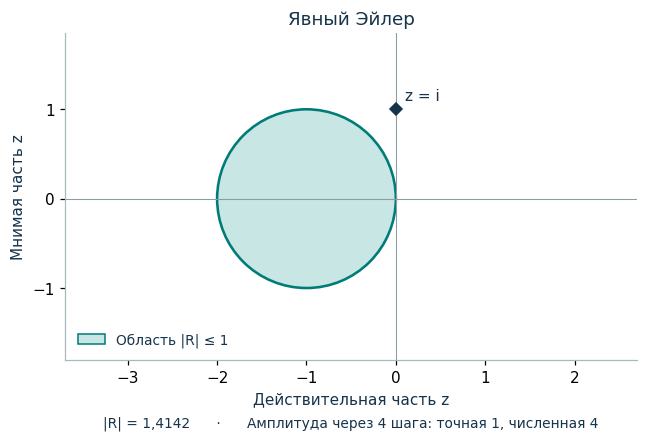

In [2]:
from matplotlib.patches import Circle, Patch

points = [("i", 1j), ("−1", -1), ("−2", -2), ("−3", -3), ("−1 + i", -1+1j)]
methods = [("Явный Эйлер", "ee"), ("Неявный Эйлер", "ie"), ("Кранк–Николсон", "cn")]


def region_figure(method="ee", point=1j):
    z = complex(point)
    if method == "ee":
        R = 1+z
    elif method == "ie":
        R = 1/(1-z)
    else:
        R = (1+z/2)/(1-z/2)
    fig, ax = plt.subplots(figsize=(7.5, 3.9), constrained_layout=True)
    fill = "#C8E6E3"
    if method == "cn":
        ax.axvspan(-3.7, 0, facecolor=fill)
        ax.axvline(0, color=TEAL, lw=1.8)
    else:
        if method == "ie":
            ax.set_facecolor(fill)
        center = -1 if method == "ee" else 1
        ax.add_patch(Circle((center, 0), radius=1, edgecolor=TEAL,
                            facecolor=fill if method=="ee" else "white", lw=1.7))
        ax.axvline(0, lw=.7, color="#8C9CA2")
    ax.axhline(0, lw=.7, color="#8C9CA2")
    ax.plot(z.real, z.imag, "D", color=INK, ms=6)
    z_label = next(label for label, val in points if val == point)
    ax.annotate("z = " + z_label, (z.real,z.imag), xytext=(6, 6), textcoords="offset points")
    ax.set(xlim=(-3.7,2.7), ylim=(-1.8,1.85), xticks=np.arange(-3,3), yticks=[-1,0,1],
           aspect="equal", title=next(label for label,val in methods if val == method),
           xlabel="Действительная часть z", ylabel="Мнимая часть z")
    ax.legend(handles=[Patch(facecolor=fill, edgecolor=TEAL, label="Область |R| ≤ 1")],
              frameon=False, fontsize=9, loc="lower left")
    fig.supxlabel(f"|R| = {decimal(abs(R), 4)}      ·      Амплитуда через 4 шага:"
                  f" точная {decimal(np.exp(4*z.real), 6)}, численная {decimal(abs(R)**4, 6)}",
                  fontsize=9)
    return fig


experiment(region_figure, {"method": ("Метод", methods, "ee"), "point": ("Точка z", points, 1j)})

Метод называют **A-устойчивым**, если его область абсолютной устойчивости содержит всю левую полуплоскость $\operatorname{Re}z\le0$. Этим свойством обладают неявный Эйлер и схема Кранка–Николсон. При больших отрицательных $z$ между ними видно различие. Точное решение за шаг почти полностью затухает. У неявного Эйлера $R(z)$ тоже стремится к нулю, а у Кранка–Николсон — к $-1$. Дополнительное свойство A-устойчивого метода подавлять такие быстро затухающие моды, то есть иметь $R(z)\to0$ при $|z|\to\infty$ в левой полуплоскости, называют **L-устойчивостью**.

## 4. Две схемы переноса

Уравнение $u_t+c u_x=0$, где $c>0$, переносит профиль вправо. Число

$$
C=\frac{c\tau}{h}
$$

показывает, сколько ячеек сетки точный профиль проходит за один шаг по времени. Его называют **числом Куранта**.

Возьмём явный Эйлер по времени и сравним две формулы для пространственной производной.

| Разность по пространству | Схема | Множитель гармоники |
|---|---|---|
| Центральная | $\displaystyle U_k^{s+1}=U_k^s-\frac C2(U_{k+1}^s-U_{k-1}^s)$ | $G(\theta)=1-iC\sin\theta$ |
| Левая, против потока | $\displaystyle U_k^{s+1}=(1-C)U_k^s+CU_{k-1}^s$ | $G(\theta)=1-C+Ce^{-i\theta}$ |

При $0\le C\le1$ схема против потока берёт взвешенное среднее двух соседних значений, и для всех гармоник $|G|\le1$. При $C=1$ получается точный сдвиг на одну ячейку.

У центральной схемы

$$
|G(\theta)|=\sqrt{1+C^2\sin^2\theta}.
$$

Любопытно, **какая именно гармоника растёт быстрее всего**. У чередования $1,-1,1,-1,\ldots$ угол равен $\pi$, и множитель равен единице. Наибольшее усиление достигается при $\theta=\pi/2$, то есть когда на период приходятся четыре шага сетки.

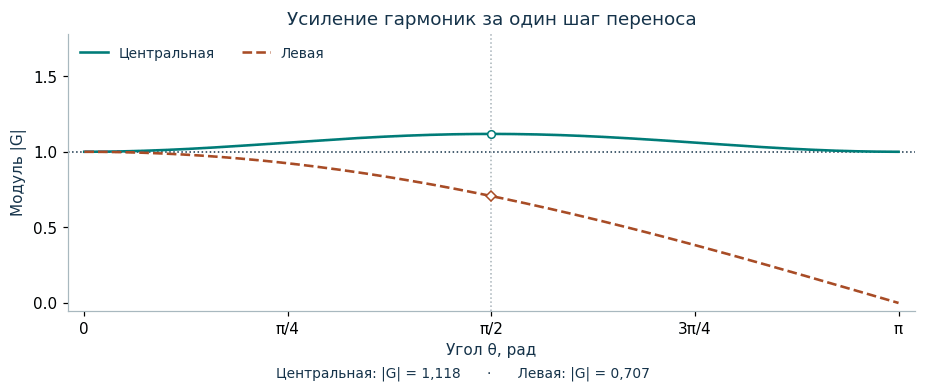

In [3]:
def advection_factor(theta, C, upwind):
    if upwind:
        return 1 - C + C*np.exp(-1j*theta)
    return 1 - 1j*C*np.sin(theta)


def spectrum_figure(C=0.5, fraction=0.5, visible=(True, True)):
    fig, ax = plt.subplots(figsize=(8.3, 3.45), constrained_layout=True)
    angles = np.linspace(0, np.pi, 251)
    chosen = np.pi * fraction
    ax.axhline(1, color=INK, ls=":", lw=1)
    ax.axvline(chosen, color="#A7B3B7", ls=":", lw=1)
    readings = []
    for upwind, label, color, ls, marker in (
            (False,"Центральная",TEAL,"-","o"), (True,"Левая",RUST,"--","D")):
        if visible[int(upwind)]:
            ax.plot(angles, np.abs(advection_factor(angles, C, upwind)),
                    color=color, ls=ls, lw=1.7, label=label)
            value = abs(advection_factor(chosen, C, upwind))
            ax.plot(chosen,value,marker,ms=5,mec=color,mfc="white")
            readings.append(label + ": |G| = " + decimal(value))
    if any(visible):
        ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=9)
    ax.set(xlim=(-.02*np.pi,1.02*np.pi), ylim=(-.05,1.78),
           xticks=np.linspace(0,np.pi,5), xticklabels=["0","π/4","π/2","3π/4","π"],
           yticks=[0,.5,1,1.5], title="Усиление гармоник за один шаг переноса",
           xlabel="Угол θ, рад", ylabel="Модуль |G|")
    fig.supxlabel("      ·      ".join(readings), fontsize=9)
    return fig


experiment(spectrum_figure, {
    "C": ("Число Куранта C", [(decimal(c), c) for c in (.25,.5,.75,1.,1.25)], .5),
    "fraction": ("Фаза между соседями", list(zip(["0","π/4","π/2","3π/4","π"], np.arange(5)/4)), .5)
}, ("Центральная разность","Левая разность"))

## 5. Почему одного гладкого расчёта недостаточно?

Пусть $c=1$, начальный профиль равен $\cos(2\pi x)$, а конечное время $T=1/2$. К этому моменту точный косинус сдвинется на половину периода. Во всех опытах ниже сравнение проводится **в один и тот же физический момент**.

Сначала возьмём центральную схему и $\tau=h/2$. Тогда $C=1/2$, а до времени $T$ нужно сделать ровно $N$ шагов. При измельчении сетки численный косинус всё ближе к точному. Но этот расчёт показывает поведение только первой гармоники.

У гармоники с четырьмя шагами на период множитель за один шаг равен по модулю $\sqrt{1+1/4}$. На сетке из 32 узлов её полное усиление равно примерно $35{,}5$. На сетке из 128 узлов — уже **1,59 миллиона**. График длинного косинуса улучшается, а единой оценки $K_T$ для всех возмущений нет.

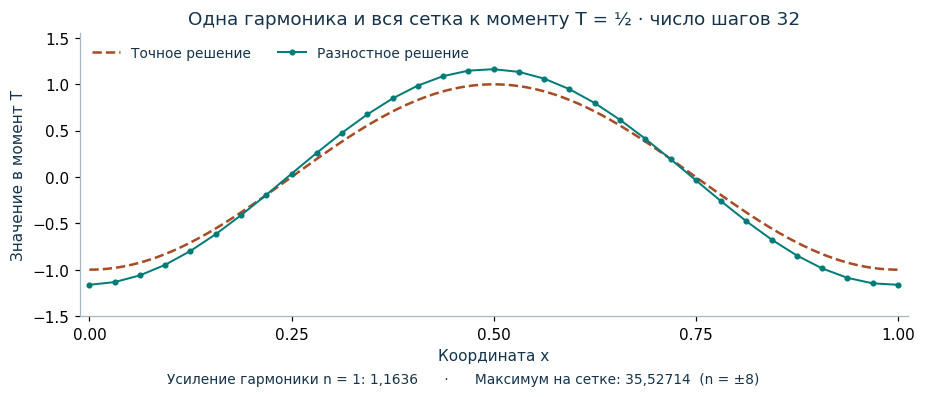

In [4]:
def refinement_data(N, preset):
    h = 1 / N
    tau = h*h/2 if preset == "small" else h/2
    steps = round(0.5/tau)
    modes = np.arange(N//2+1)
    factors = advection_factor(2*np.pi*modes/N, tau/h, preset == "upwind")
    amplitudes = np.abs(factors)**steps
    return steps, factors[1]**steps, amplitudes


def format_gain(value):
    if value < 1e5:
        return decimal(value, 5)
    power = int(np.floor(np.log10(value)))
    return "$" + f"{value/10**power:.3f}".replace(".", "{,}") + rf"\cdot10^{{{power}}}" + "$"


def refinement_figure(preset="center", N=32, visible=(True, True)):
    steps, smooth, gains = refinement_data(N, preset)
    fig, ax = plt.subplots(figsize=(8.3,3.5), constrained_layout=True)
    x = np.linspace(0,1,401)
    nodes = np.arange(N+1)/N
    if visible[0]:
        ax.plot(x, -np.cos(2*np.pi*x), "--", lw=1.65, color=RUST, label="Точное решение")
    if visible[1]:
        ax.plot(nodes, np.real(smooth*np.exp(2j*np.pi*nodes)), "-o", color=TEAL,
                ms=3 if N <= 64 else 1.5, lw=1.3, label="Разностное решение")
    if any(visible):
        ax.legend(loc="upper left", ncol=2, frameon=False, fontsize=9)
    nmax = np.argmax(gains)
    mode = "0" if nmax == 0 else f"±{nmax}"
    ax.set(xlim=(-.012,1.012), ylim=(-1.5,1.55), xticks=np.arange(5)/4,
           xlabel="Координата x",ylabel="Значение в момент T",
           title=f"Одна гармоника и вся сетка к моменту T = ½ · число шагов {steps}")
    fig.supxlabel("Усиление гармоники n = 1: " + format_gain(abs(smooth))
                  + "      ·      Максимум на сетке: " + format_gain(gains[nmax])
                  + f"  (n = {mode})", fontsize=9)
    return fig


experiment(refinement_figure, {
    "preset": ("Схема и шаг", [("Центральная, τ = h/2","center"),
                              ("Против потока, τ = h/2","upwind"),
                              ("Центральная, τ = h²/2","small")], "center"),
    "N": ("Число узлов N", [16,32,64,128,256], 32)
}, ("Точное решение","Разностное решение"))

Если у той же центральной схемы взять $\tau=h^2/2$, результат меняется. Теперь $C=1/(2N)$. До времени $T=1/2$ требуется $N^2$ шагов, зато наибольшее усиление за один шаг становится всё ближе к единице. Полное усиление равно

$$
\left(1+\frac{1}{4N^2}\right)^{N^2/2}
\longrightarrow e^{1/8}\approx1{,}133.
$$

Здесь есть гармоники с $|G|>1$ на каждой сетке, **и схема устойчива при выбранной связи шагов**. Для любого фиксированного $T$ полное усиление ограничено числом $e^{T/4}$. Именно усиление за фиксированное физическое время стоит в определении устойчивости.